<a href="https://colab.research.google.com/github/razokiyassine/Network-Intrusion-Detection/blob/main/TP_NSL_KDD_Random_Forest_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import os
import time
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.model_selection import (
    train_test_split, StratifiedKFold, RandomizedSearchCV
)
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report, confusion_matrix
)

RANDOM_STATE = 42
CLASSES = ["Normal", "DoS", "Probe", "R2L", "U2R"]

# Configuration d'exécution
MODE_RAPIDE = True
TAILLE_TRAIN_RAPIDE = 50000
TAILLE_CV = 20000
OPTIMISER = True

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)

print("Bibliothèques importées avec succès.")

Bibliothèques importées avec succès.


In [9]:
BASE_URL = (
    "https://raw.githubusercontent.com/"
    "jmnwong/NSL-KDD-Dataset/master/"
)

fichiers = ["KDDTrain+.txt", "KDDTest+.txt"]

for fichier in fichiers:
    if not os.path.exists(fichier):
        try:
            url = BASE_URL + fichier.replace("+", "%2B")
            urllib.request.urlretrieve(url, fichier)
            print("Téléchargé :", fichier)
        except Exception as e:
            print("Téléchargement impossible :", fichier, e)

manquants = [f for f in fichiers if not os.path.exists(f)]

if manquants:
    from google.colab import files
    print("Importe les fichiers manquants :", manquants)
    files.upload()

assert all(os.path.exists(f) for f in fichiers), \
    "Les deux fichiers .txt sont nécessaires."

print("Dataset disponible.")

Téléchargé : KDDTrain+.txt
Téléchargé : KDDTest+.txt
Dataset disponible.


In [10]:
features = [
    "duration", "protocol_type", "service", "flag",
    "src_bytes", "dst_bytes", "land", "wrong_fragment",
    "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted",
    "num_root", "num_file_creations", "num_shells",
    "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login",
    "count", "srv_count", "serror_rate",
    "srv_serror_rate", "rerror_rate", "srv_rerror_rate",
    "same_srv_rate", "diff_srv_rate", "srv_diff_host_rate",
    "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate"
]

assert len(features) == 41

colonnes = features + ["attack_type", "difficulty"]

train_df = pd.read_csv(
    "KDDTrain+.txt", header=None, names=colonnes
)

test_df = pd.read_csv(
    "KDDTest+.txt", header=None, names=colonnes
)

print("Train :", train_df.shape)
print("Test  :", test_df.shape)

print("\nAperçu des données :")
display(train_df.head())

print("\nTypes des variables :")
display(train_df.dtypes.value_counts())

Train : (125973, 43)
Test  : (22544, 43)

Aperçu des données :


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,root_shell,su_attempted,num_root,num_file_creations,num_shells,num_access_files,num_outbound_cmds,is_host_login,is_guest_login,count,srv_count,serror_rate,srv_serror_rate,rerror_rate,srv_rerror_rate,same_srv_rate,diff_srv_rate,srv_diff_host_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,attack_type,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,2,0.0,0.0,0.0,0.0,1.00,0.00,0.00,150,25,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,13,1,0.0,0.0,0.0,0.0,0.08,0.15,0.00,255,1,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,123,6,1.0,1.0,0.0,0.0,0.05,0.07,0.00,255,26,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,5,5,0.2,0.2,0.0,0.0,1.00,0.00,0.00,30,255,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,30,32,0.0,0.0,0.0,0.0,1.00,0.00,0.09,255,255,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21



Types des variables :


,count
int64,24
float64,15
object,4


In [11]:
attack_groups = {
    "Normal": [
        "normal"
    ],

    "DoS": [
        "back", "land", "neptune", "pod", "smurf",
        "teardrop", "apache2", "mailbomb",
        "processtable", "udpstorm", "worm"
    ],

    "Probe": [
        "ipsweep", "nmap", "portsweep",
        "satan", "mscan", "saint"
    ],

    "R2L": [
        "ftp_write", "guess_passwd", "imap",
        "multihop", "phf", "spy", "warezclient",
        "warezmaster", "httptunnel", "http_tunnel",
        "named", "sendmail", "snmpgetattack",
        "snmpguess", "xlock", "xsnoop"
    ],

    "U2R": [
        "buffer_overflow", "loadmodule", "perl",
        "rootkit", "ps", "sqlattack", "xterm"
    ]
}

attack_mapping = {
    attack: group
    for group, attacks in attack_groups.items()
    for attack in attacks
}

for df in [train_df, test_df]:

    df["attack_type"] = (
        df["attack_type"]
        .astype(str)
        .str.strip()
        .str.lower()
        .str.rstrip(".")
    )

    inconnues = (
        set(df["attack_type"].unique())
        - set(attack_mapping.keys())
    )

    if inconnues:
        raise ValueError(
            f"Types d'attaques non reconnus : {inconnues}"
        )

    df["attack_group"] = df["attack_type"].map(
        attack_mapping
    )

print("Regroupement terminé.")

print("\nRépartition Train :")
print(train_df["attack_group"].value_counts())

print("\nRépartition Test :")
print(test_df["attack_group"].value_counts())

Regroupement terminé.

Répartition Train :
attack_group
Normal    67343
DoS       45927
Probe     11656
R2L         995
U2R          52
Name: count, dtype: int64

Répartition Test :
attack_group
Normal    9711
DoS       7460
R2L       2885
Probe     2421
U2R         67
Name: count, dtype: int64


In [12]:
categorical_cols = [
    "protocol_type", "service", "flag"
]

numeric_cols = [
    col for col in features
    if col not in categorical_cols
]

for df in [train_df, test_df]:

    for col in numeric_cols:
        df[col] = pd.to_numeric(
            df[col], errors="coerce"
        )

    for col in categorical_cols:
        df[col] = df[col].fillna("missing").astype(str)

print("=== DIAGNOSTIC ===")

diagnostic = pd.DataFrame({
    "Dataset": ["Train", "Test"],
    "Observations": [len(train_df), len(test_df)],
    "Variables": [len(features), len(features)],
    "Valeurs manquantes": [
        train_df[features].isna().sum().sum(),
        test_df[features].isna().sum().sum()
    ],
    "Doublons": [
        train_df.duplicated().sum(),
        test_df.duplicated().sum()
    ]
})

display(diagnostic)

constantes = [
    col for col in features
    if train_df[col].nunique(dropna=False) <= 1
]

print("Variables constantes :", constantes)

features_utilisees = [
    col for col in features
    if col not in constantes
]

numeric_used = [
    col for col in numeric_cols
    if col in features_utilisees
]

categorical_used = [
    col for col in categorical_cols
    if col in features_utilisees
]

print("Variables conservées :", len(features_utilisees))

=== DIAGNOSTIC ===


,Dataset,Observations,Variables,Valeurs manquantes,Doublons
0,Train,125973,41,0,0
1,Test,22544,41,0,0


Variables constantes : ['num_outbound_cmds']
Variables conservées : 40


,Train,Test,Train (%),Test (%)
attack_group,,,,
Normal,67343,9711,53.458,43.076
DoS,45927,7460,36.458,33.091
Probe,11656,2421,9.253,10.739
R2L,995,2885,0.790,12.797
U2R,52,67,0.041,0.297


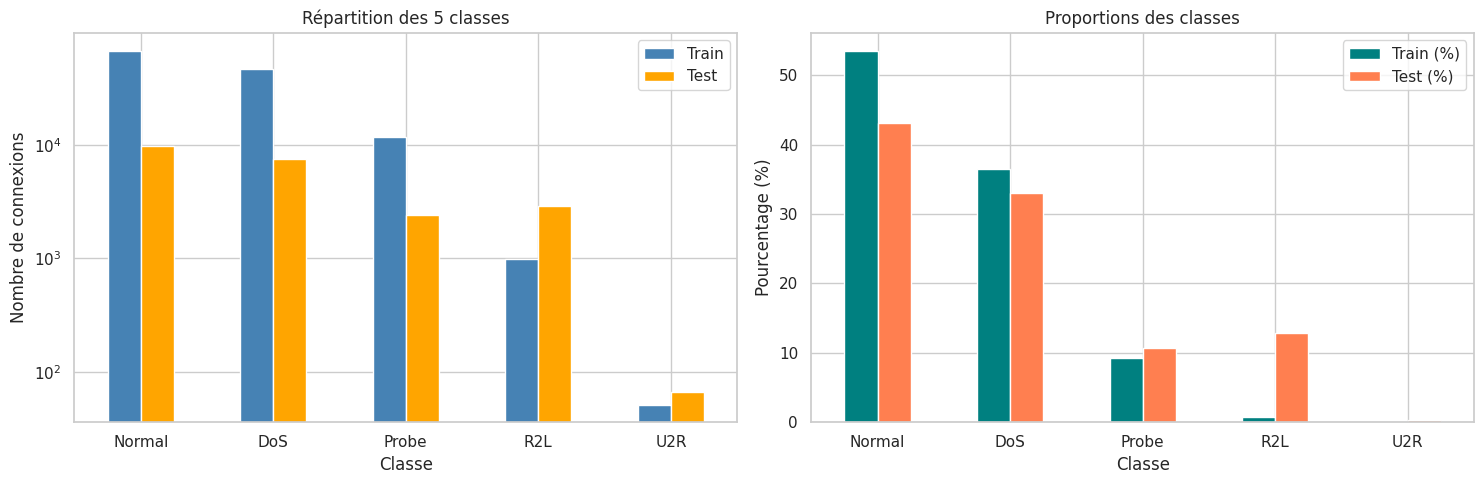

In [13]:
distribution = pd.DataFrame({
    "Train": train_df["attack_group"]
        .value_counts()
        .reindex(CLASSES, fill_value=0),

    "Test": test_df["attack_group"]
        .value_counts()
        .reindex(CLASSES, fill_value=0)
})

distribution["Train (%)"] = (
    distribution["Train"] / len(train_df) * 100
)

distribution["Test (%)"] = (
    distribution["Test"] / len(test_df) * 100
)

display(distribution.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

distribution[["Train", "Test"]].plot(
    kind="bar",
    ax=axes[0],
    color=["steelblue", "orange"]
)

axes[0].set_title("Répartition des 5 classes")
axes[0].set_ylabel("Nombre de connexions")
axes[0].set_xlabel("Classe")
axes[0].tick_params(axis="x", rotation=0)
axes[0].set_yscale("log")

distribution[["Train (%)", "Test (%)"]].plot(
    kind="bar",
    ax=axes[1],
    color=["teal", "coral"]
)

axes[1].set_title("Proportions des classes")
axes[1].set_ylabel("Pourcentage (%)")
axes[1].set_xlabel("Classe")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()

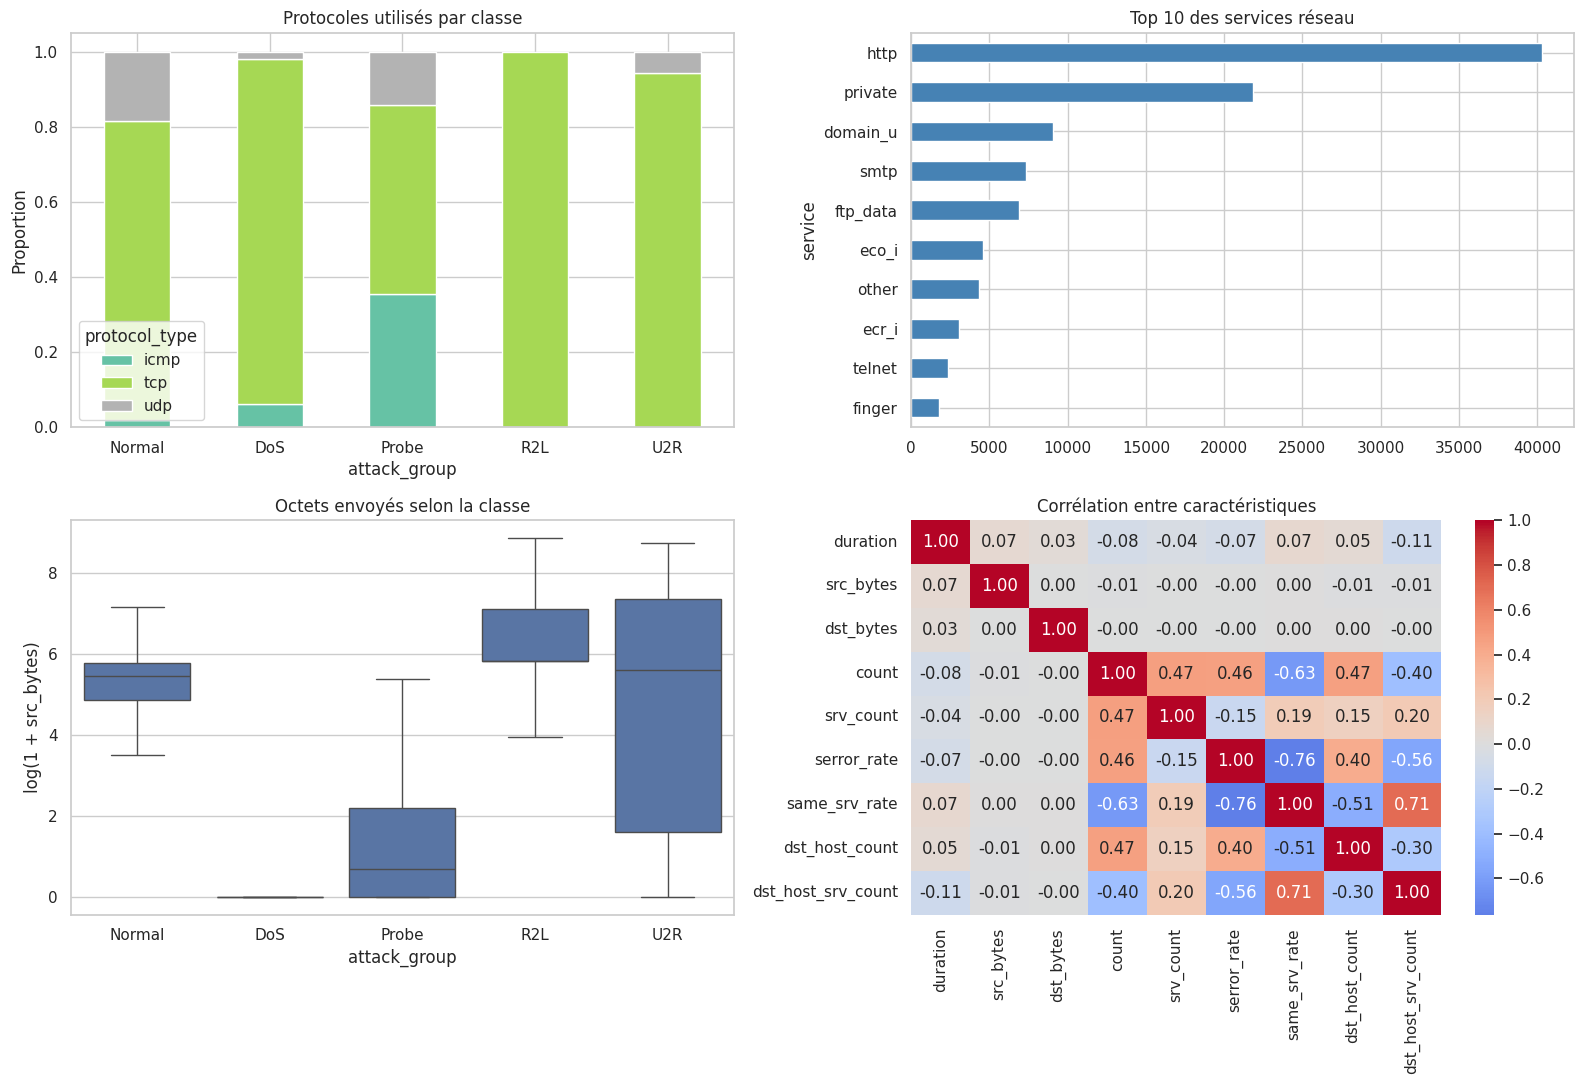

In [14]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# 1. Protocoles par classe
protocol_dist = pd.crosstab(
    train_df["attack_group"],
    train_df["protocol_type"],
    normalize="index"
).reindex(CLASSES).fillna(0)

protocol_dist.plot(
    kind="bar",
    stacked=True,
    ax=axes[0, 0],
    colormap="Set2"
)

axes[0, 0].set_title("Protocoles utilisés par classe")
axes[0, 0].set_ylabel("Proportion")
axes[0, 0].tick_params(axis="x", rotation=0)

# 2. Top 10 des services
train_df["service"].value_counts().head(10).plot(
    kind="barh",
    ax=axes[0, 1],
    color="steelblue"
)

axes[0, 1].set_title("Top 10 des services réseau")
axes[0, 1].invert_yaxis()

# 3. Volumes d'octets envoyés
train_df["log_src_bytes"] = np.log1p(
    train_df["src_bytes"].clip(lower=0)
)

sns.boxplot(
    data=train_df,
    x="attack_group",
    y="log_src_bytes",
    order=CLASSES,
    ax=axes[1, 0],
    showfliers=False
)

axes[1, 0].set_title("Octets envoyés selon la classe")
axes[1, 0].set_ylabel("log(1 + src_bytes)")

# 4. Corrélations
corr_cols = [
    "duration", "src_bytes", "dst_bytes",
    "count", "srv_count", "serror_rate",
    "same_srv_rate", "dst_host_count",
    "dst_host_srv_count"
]

sns.heatmap(
    train_df[corr_cols].corr(),
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f",
    ax=axes[1, 1]
)

axes[1, 1].set_title("Corrélation entre caractéristiques")

plt.tight_layout()
plt.show()

In [15]:
X_train_full = train_df[features_utilisees].copy()
y_train_full = train_df["attack_group"].copy()

X_test = test_df[features_utilisees].copy()
y_test = test_df["attack_group"].copy()

if MODE_RAPIDE:

    X_train, _, y_train, _ = train_test_split(
        X_train_full,
        y_train_full,
        train_size=TAILLE_TRAIN_RAPIDE,
        stratify=y_train_full,
        random_state=RANDOM_STATE
    )

else:
    X_train = X_train_full
    y_train = y_train_full

# Sous-ensemble utilisé uniquement pour
# sélectionner les hyperparamètres
if len(X_train) > TAILLE_CV:

    X_cv, _, y_cv, _ = train_test_split(
        X_train,
        y_train,
        train_size=TAILLE_CV,
        stratify=y_train,
        random_state=RANDOM_STATE
    )

else:
    X_cv, y_cv = X_train, y_train

print("Train final :", X_train.shape)
print("Train pour CV :", X_cv.shape)
print("Test officiel :", X_test.shape)

print("\nRépartition des classes dans Train :")
print(y_train.value_counts())

Train final : (50000, 40)
Train pour CV : (20000, 40)
Test officiel : (22544, 40)

Répartition des classes dans Train :
attack_group
Normal    26729
DoS       18229
Probe      4626
R2L         395
U2R          21
Name: count, dtype: int64


In [16]:
def creer_pretraitement(standardiser=False):

    etapes_num = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if standardiser:
        etapes_num.append(
            ("scaler", StandardScaler())
        )

    pipeline_num = Pipeline(etapes_num)

    pipeline_cat = Pipeline([
        ("imputer", SimpleImputer(
            strategy="most_frequent"
        )),
        ("encoder", OneHotEncoder(
            handle_unknown="ignore"
        ))
    ])

    return ColumnTransformer(
        transformers=[
            ("num", pipeline_num, numeric_used),
            ("cat", pipeline_cat, categorical_used)
        ],
        sparse_threshold=0.5
    )


modeles = {

    "Decision Tree": Pipeline([
        ("preprocess", creer_pretraitement()),
        ("classifier", DecisionTreeClassifier(
            max_depth=15,
            class_weight="balanced",
            random_state=RANDOM_STATE
        ))
    ]),

    "Random Forest": Pipeline([
        ("preprocess", creer_pretraitement()),
        ("classifier", RandomForestClassifier(
            n_estimators=150,
            max_depth=None,
            class_weight="balanced_subsample",
            bootstrap=True,
            oob_score=True,
            n_jobs=-1,
            random_state=RANDOM_STATE
        ))
    ]),

    "SVM RBF": Pipeline([
        ("preprocess", creer_pretraitement(
            standardiser=True
        )),
        ("classifier", SVC(
            kernel="rbf",
            C=2,
            gamma="scale",
            class_weight="balanced",
            cache_size=500
        ))
    ])
}

print("Trois modèles créés :")
for nom in modeles:
    print("-", nom)

Trois modèles créés :
- Decision Tree
- Random Forest
- SVM RBF


In [17]:
grilles = {

    "Decision Tree": {
        "classifier__max_depth": [8, 15, None],
        "classifier__min_samples_leaf": [1, 3, 5]
    },

    "Random Forest": {
        "classifier__n_estimators": [100, 150, 250],
        "classifier__max_depth": [12, None],
        "classifier__min_samples_leaf": [1, 3],
        "classifier__max_features": ["sqrt", "log2"],
        "classifier__criterion": ["gini", "entropy"]
    },

    "SVM RBF": {
        "classifier__C": [0.5, 2, 10],
        "classifier__gamma": ["scale", "auto"]
    }
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

historique_cv = []

if OPTIMISER:

    for nom, modele in modeles.items():

        print("\nOptimisation :", nom)

        recherche = RandomizedSearchCV(
            estimator=modele,
            param_distributions=grilles[nom],
            n_iter=3,
            scoring="f1_macro",
            cv=cv,
            n_jobs=-1,
            random_state=RANDOM_STATE,
            refit=False
        )

        recherche.fit(X_cv, y_cv)

        modeles[nom].set_params(
            **recherche.best_params_
        )

        print("Meilleur F1 macro CV :",
              round(recherche.best_score_, 4))

        print("Paramètres :",
              recherche.best_params_)

        historique_cv.append({
            "Modèle": nom,
            "F1 macro CV": recherche.best_score_,
            "Paramètres": recherche.best_params_
        })

    display(pd.DataFrame(historique_cv))

else:
    print("Optimisation désactivée.")


Optimisation : Decision Tree
Meilleur F1 macro CV : 0.7836
Paramètres : {'classifier__min_samples_leaf': 3, 'classifier__max_depth': None}

Optimisation : Random Forest
Meilleur F1 macro CV : 0.7834
Paramètres : {'classifier__n_estimators': 250, 'classifier__min_samples_leaf': 1, 'classifier__max_features': 'sqrt', 'classifier__max_depth': 12, 'classifier__criterion': 'entropy'}

Optimisation : SVM RBF
Meilleur F1 macro CV : 0.7697
Paramètres : {'classifier__gamma': 'auto', 'classifier__C': 10}


,Modèle,F1 macro CV,Paramètres
0,Decision Tree,0.783615,"{'classifier__min_samples_leaf': 3, 'classifie..."
1,Random Forest,0.783446,"{'classifier__n_estimators': 250, 'classifier_..."
2,SVM RBF,0.769699,"{'classifier__gamma': 'auto', 'classifier__C':..."


In [18]:
resultats = []
predictions = {}
modeles_entraines = {}

for nom, modele in modeles.items():

    print("\nEntraînement :", nom)

    debut = time.perf_counter()

    modele.fit(X_train, y_train)

    duree = time.perf_counter() - debut

    pred = modele.predict(X_test)

    predictions[nom] = pred
    modeles_entraines[nom] = modele

    # Attaques classées à tort comme normales
    fn_attaques = int(np.sum(
        (y_test.to_numpy() != "Normal") &
        (pred == "Normal")
    ))

    # Trafic normal classé comme attaque
    fp_normal = int(np.sum(
        (y_test.to_numpy() == "Normal") &
        (pred != "Normal")
    ))

    resultats.append({

        "Modèle": nom,

        "Accuracy": accuracy_score(y_test, pred),

        "Precision macro": precision_score(
            y_test, pred,
            average="macro",
            zero_division=0
        ),

        "Recall macro": recall_score(
            y_test, pred,
            average="macro",
            zero_division=0
        ),

        "F1 macro": f1_score(
            y_test, pred,
            average="macro",
            zero_division=0
        ),

        "F1 weighted": f1_score(
            y_test, pred,
            average="weighted",
            zero_division=0
        ),

        "FN attaques": fn_attaques,
        "FP normal": fp_normal,

        "Coût": 20 * fn_attaques + 2 * fp_normal,

        "Temps (s)": duree
    })

resultats_df = pd.DataFrame(resultats)

resultats_df = resultats_df.sort_values(
    by="F1 macro",
    ascending=False
)

print("\n=== COMPARAISON FINALE ===")
display(resultats_df.round(4))

meilleur_nom = resultats_df.iloc[0]["Modèle"]

print("\nMeilleur modèle selon F1 macro :", meilleur_nom)

rf = modeles_entraines["Random Forest"].named_steps[
    "classifier"
]

print("Score OOB Random Forest :",
      round(rf.oob_score_, 4))


Entraînement : Decision Tree

Entraînement : Random Forest

Entraînement : SVM RBF

=== COMPARAISON FINALE ===


,Modèle,Accuracy,Precision macro,Recall macro,F1 macro,F1 weighted,FN attaques,FP normal,Coût,Temps (s)
2,SVM RBF,0.7668,0.7833,0.5580,0.5867,0.7367,4592,389,92618,17.9536
0,Decision Tree,0.7590,0.5391,0.5432,0.5041,0.7109,3598,380,72720,0.7268
1,Random Forest,0.7454,0.7885,0.4848,0.4977,0.7049,5268,262,105884,24.1061



Meilleur modèle selon F1 macro : SVM RBF
Score OOB Random Forest : 0.9969


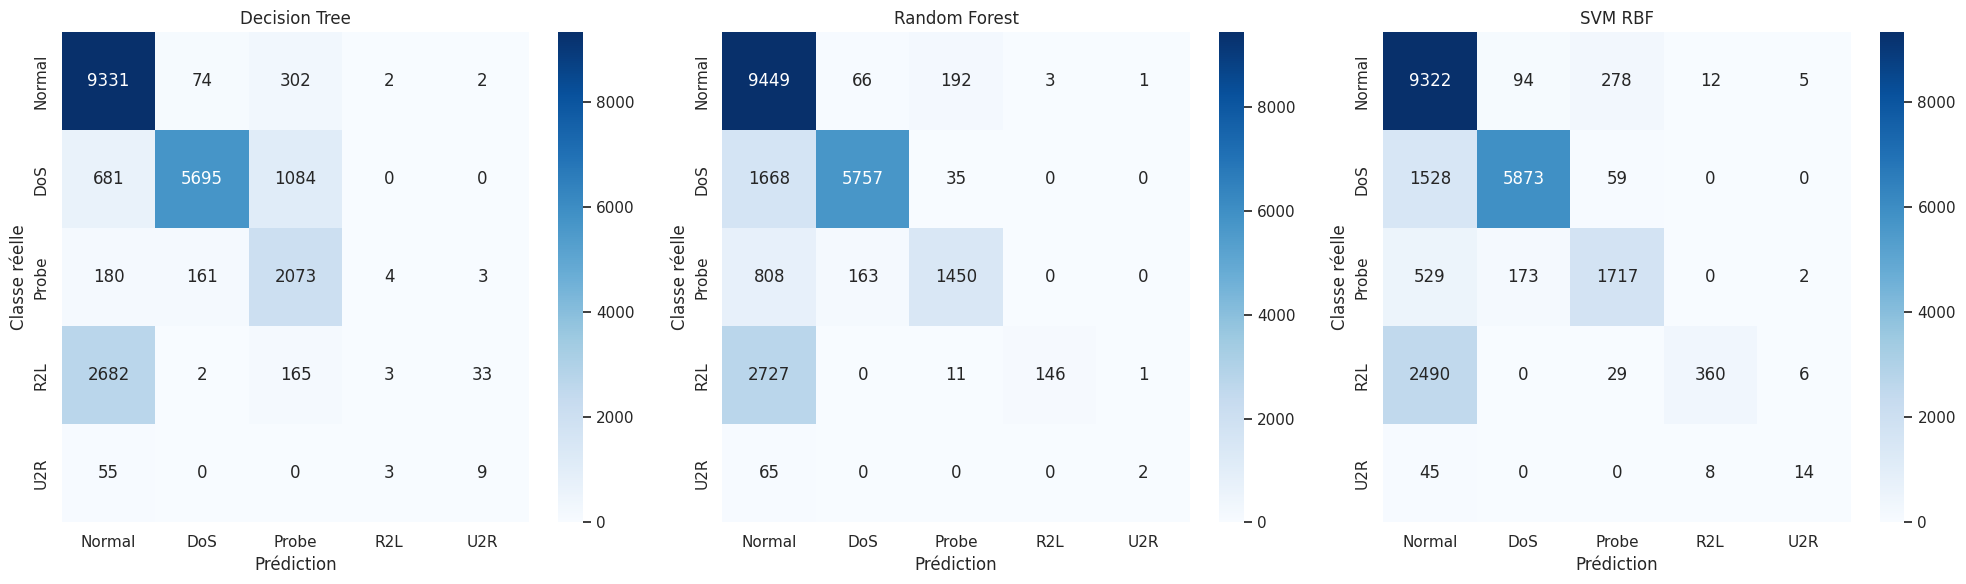


Decision Tree
              precision    recall  f1-score   support

      Normal       0.72      0.96      0.82      9711
         DoS       0.96      0.76      0.85      7460
       Probe       0.57      0.86      0.69      2421
         R2L       0.25      0.00      0.00      2885
         U2R       0.19      0.13      0.16        67

    accuracy                           0.76     22544
   macro avg       0.54      0.54      0.50     22544
weighted avg       0.72      0.76      0.71     22544


Random Forest
              precision    recall  f1-score   support

      Normal       0.64      0.97      0.77      9711
         DoS       0.96      0.77      0.86      7460
       Probe       0.86      0.60      0.71      2421
         R2L       0.98      0.05      0.10      2885
         U2R       0.50      0.03      0.06        67

    accuracy                           0.75     22544
   macro avg       0.79      0.48      0.50     22544
weighted avg       0.81      0.75      0.70    

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

for ax, (nom, pred) in zip(
    axes, predictions.items()
):

    cm = confusion_matrix(
        y_test,
        pred,
        labels=CLASSES
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=CLASSES,
        yticklabels=CLASSES,
        ax=ax
    )

    ax.set_title(nom)
    ax.set_xlabel("Prédiction")
    ax.set_ylabel("Classe réelle")

plt.tight_layout()
plt.show()

# Rapport détaillé de chaque modèle
for nom, pred in predictions.items():

    print("\n==========================")
    print(nom)
    print("==========================")

    print(classification_report(
        y_test,
        pred,
        labels=CLASSES,
        zero_division=0
    ))

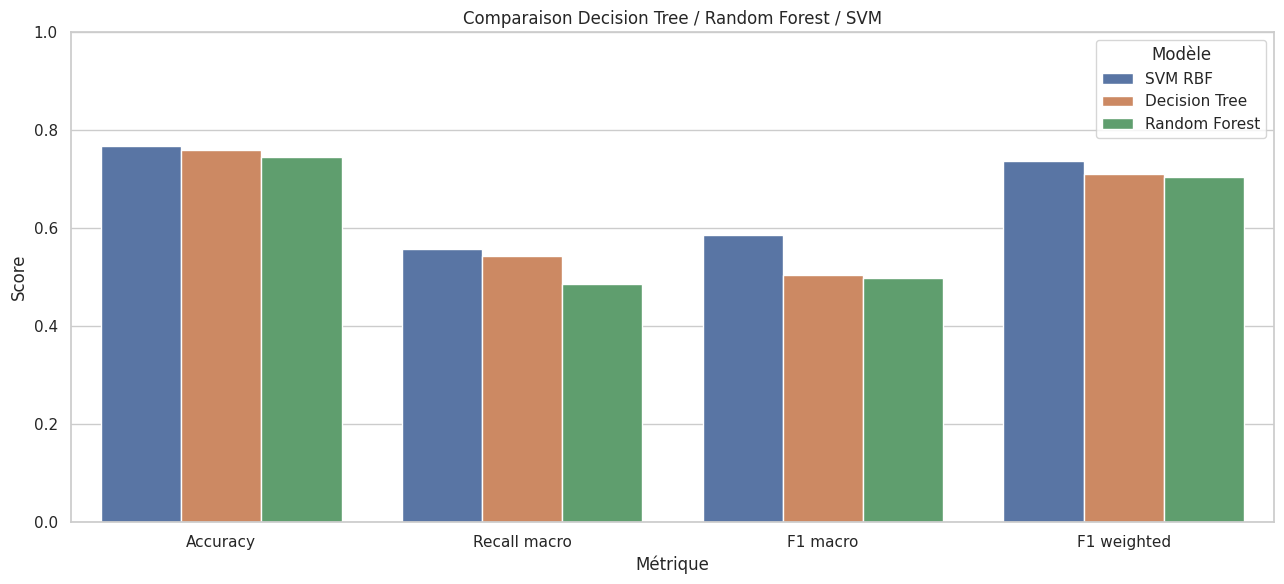

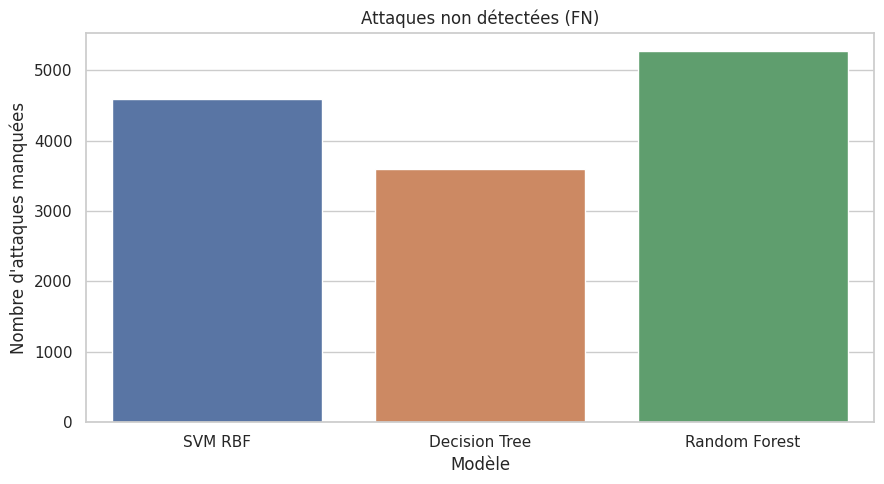

In [20]:
metriques = [
    "Accuracy",
    "Recall macro",
    "F1 macro",
    "F1 weighted"
]

data_plot = resultats_df.melt(
    id_vars="Modèle",
    value_vars=metriques,
    var_name="Métrique",
    value_name="Score"
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=data_plot,
    x="Métrique",
    y="Score",
    hue="Modèle"
)

plt.title("Comparaison Decision Tree / Random Forest / SVM")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(title="Modèle")
plt.tight_layout()
plt.show()

# Comparaison des attaques non détectées
plt.figure(figsize=(9, 5))

sns.barplot(
    data=resultats_df,
    x="Modèle",
    y="FN attaques",
    hue="Modèle",
    legend=False
)

plt.title("Attaques non détectées (FN)")
plt.ylabel("Nombre d'attaques manquées")
plt.tight_layout()
plt.show()

Top 15 caractéristiques importantes :


,Importance
service,0.114146
src_bytes,0.088144
dst_bytes,0.072994
dst_host_srv_count,0.066831
count,0.057010
logged_in,0.051154
flag,0.049063
dst_host_diff_srv_rate,0.041478
protocol_type,0.037486
srv_count,0.035266


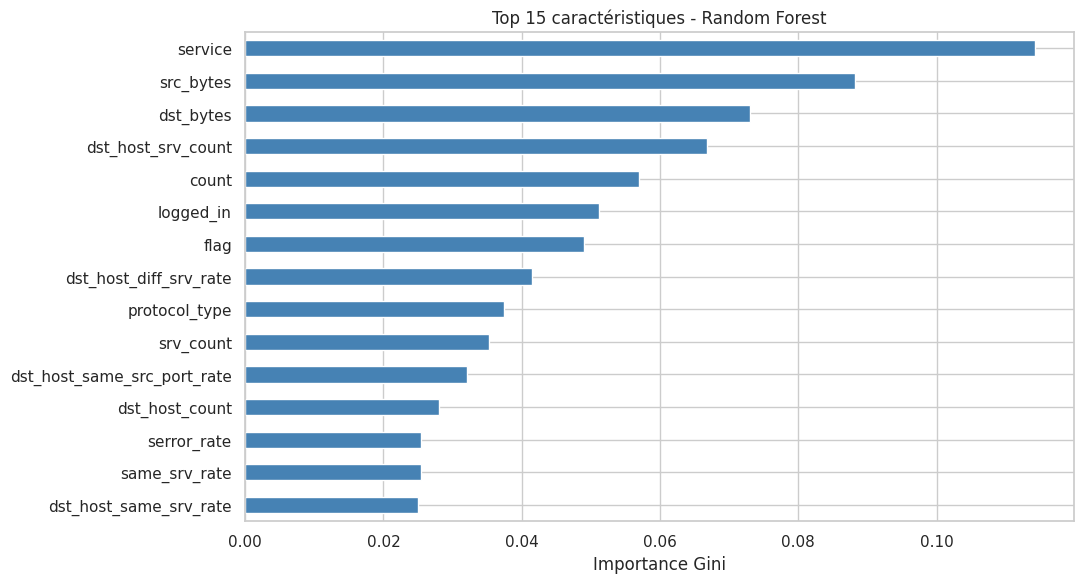


========= CONCLUSION =========
Meilleur modèle : SVM RBF
Accuracy : 0.7668
F1 macro : 0.5867
Recall macro : 0.558
FN attaques : 4592
Coût opérationnel : 92618

Attention : les classes R2L et U2R
doivent être étudiées individuellement.
Une bonne accuracy ne garantit pas
une bonne détection des attaques rares.

Résultats enregistrés en CSV.


In [21]:
modele_rf = modeles_entraines["Random Forest"]

preproc_rf = modele_rf.named_steps["preprocess"]
classif_rf = modele_rf.named_steps["classifier"]

noms_transformes = preproc_rf.get_feature_names_out()

importances = pd.Series(
    classif_rf.feature_importances_,
    index=noms_transformes
)

# Regrouper les colonnes One-Hot
# pour revenir aux caractéristiques originales
importance_originale = {}

for col in features_utilisees:

    if col in numeric_used:
        valeur = importances.get("num__" + col, 0)

    else:
        prefixe = "cat__" + col + "_"

        valeur = importances[
            importances.index.str.startswith(prefixe)
        ].sum()

    importance_originale[col] = valeur

importance_df = pd.Series(
    importance_originale
).sort_values(ascending=False)

print("Top 15 caractéristiques importantes :")
display(importance_df.head(15).to_frame("Importance"))

plt.figure(figsize=(11, 6))

importance_df.head(15).sort_values().plot(
    kind="barh",
    color="steelblue"
)

plt.title("Top 15 caractéristiques - Random Forest")
plt.xlabel("Importance Gini")
plt.tight_layout()
plt.show()

# Conclusion automatique
meilleur = resultats_df.iloc[0]

print("\n========= CONCLUSION =========")

print("Meilleur modèle :", meilleur["Modèle"])
print("Accuracy :", round(meilleur["Accuracy"], 4))
print("F1 macro :", round(meilleur["F1 macro"], 4))
print("Recall macro :", round(meilleur["Recall macro"], 4))
print("FN attaques :", int(meilleur["FN attaques"]))
print("Coût opérationnel :", int(meilleur["Coût"]))

print("\nAttention : les classes R2L et U2R")
print("doivent être étudiées individuellement.")
print("Une bonne accuracy ne garantit pas")
print("une bonne détection des attaques rares.")

# Enregistrer les résultats
resultats_df.to_csv(
    "comparaison_NSL_KDD_5_classes.csv",
    index=False
)

print("\nRésultats enregistrés en CSV.")